# CVAE — Arquitectura B (Provincia-Dia)

Una muestra = un dia de una provincia.
x: vector de 24 dimensiones (perfil horario de una provincia).
c: clima de esa provincia + calendario + indicadores socioeconomicos.

El modelo aprende una regla general: alta poblacion + industria implica alta demanda.
Los indicadores socioeconomicos tienen variacion real entre muestras.

In [16]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import pickle
import json
import matplotlib.pyplot as plt
import torch

project_root = Path.cwd().parent
sys.path.append(str(project_root / 'src'))

from preprocessing_b import run_preprocessing_b
from cvae import CVAE
from train_cvae import train, set_seed
from evaluate_cvae import full_evaluation, generate_scenarios

SPLITS_DIR  = project_root / 'data' / 'splits'
PROCESSED_DIR = project_root / 'data' / 'processed'
RESULTS_DIR = project_root / 'results'
RESULTS_DIR.mkdir(exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

Device: cpu


## 1. Preprocessing Architecture B

Construimos el dataset en formato provincia-dia.
El split temporal se hace por fecha — no por provincia.

In [18]:
data_b = run_preprocessing_b(
    processed_dir=PROCESSED_DIR,
    save_dir=SPLITS_DIR,
)

X_train = data_b['X_train']
X_val   = data_b['X_val']
X_test  = data_b['X_test']
C_train = data_b['C_train']
C_val   = data_b['C_val']
C_test  = data_b['C_test']

provinces_test = data_b['provinces_test']
x_scaler_b     = data_b['x_scaler']

print(f'X_train: {X_train.shape}, C_train: {C_train.shape}')
print(f'x_dim={X_train.shape[1]}, c_dim={C_train.shape[1]}')

x_wide:      (2311, 529)
clima:       (50842, 14)
calendario:  (2311, 4)
indicadores: (22, 5)

x_long: (50842, 26)  (50842 province-day samples)
c_long: (50842, 21)

Despues de eliminar dias anomalos: 50776 samples

Split:
  train: 32054 samples (1457 dias × 22 provincias)
  val:   8052 samples
  test:  10670 samples

Shapes finales:
  X_train: (32054, 24), X_val: (8052, 24), X_test: (10670, 24)
  C_train: (32054, 19), C_val: (8052, 19), C_test: (10670, 19)
  x_dim: 24, c_dim: 19

Archivos guardados en c:\Users\pazbi\OneDrive\Escritorio\ml\tp_final_ml\provincias\data\splits/ con prefijo 'b_'
X_train: (32054, 24), C_train: (32054, 19)
x_dim=24, c_dim=19


## 2. Definir y entrenar el modelo

In [19]:
CONFIG_B = {
    'lr':            1e-3,
    'batch_size':    512,
    'max_epochs':    300,
    'patience':      30,
    'beta':          0.01,
    'warmup_epochs': 50,
    'free_bits':     2.0,
    'seed':          42,
    'device':        DEVICE,
}

model_b = CVAE(
    x_dim=X_train.shape[1],
    c_dim=C_train.shape[1],
    hidden_dims=[64, 64],    # ← más chico que 128
    latent_dim=8,
)
print(model_b)

CVAE(
  (encoder): Encoder(
    (net): Sequential(
      (0): Linear(in_features=43, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (5): GELU(approximate='none')
    )
    (mu): Linear(in_features=64, out_features=8, bias=True)
    (logvar): Linear(in_features=64, out_features=8, bias=True)
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=27, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (5): GELU(approximate='none')
    )
    (out): Linear(in_features=64, out_features=24, bias=True)
  )
)


In [20]:
history_b = train(
    model_b,
    X_train, C_train,
    X_val,   C_val,
    config=CONFIG_B,
    save_path=RESULTS_DIR / 'cvae_b_checkpoint.pt',
)

Training on cpu | x_dim=24 | c_dim=19 | latent_dim=8
Train: 32054 samples | Val: 8052 samples
------------------------------------------------------------
Epoch 001 | beta=0.000 | train=0.5564 (r=0.5559 kl=2.1202) | val=0.2225 (r=0.2220 kl=2.3744)
Epoch 010 | beta=0.002 | train=0.0100 (r=0.0057 kl=2.1689) | val=0.0092 (r=0.0048 kl=2.1621)
Epoch 020 | beta=0.004 | train=0.0108 (r=0.0026 kl=2.0564) | val=0.0106 (r=0.0023 kl=2.0548)
Epoch 030 | beta=0.006 | train=0.0139 (r=0.0017 kl=2.0308) | val=0.0136 (r=0.0014 kl=2.0314)

Early stopping at epoch 39 (best val loss: 0.0091)
Checkpoint guardado en c:\Users\pazbi\OneDrive\Escritorio\ml\tp_final_ml\provincias\results\cvae_b_checkpoint.pt


## 3. Curvas de entrenamiento

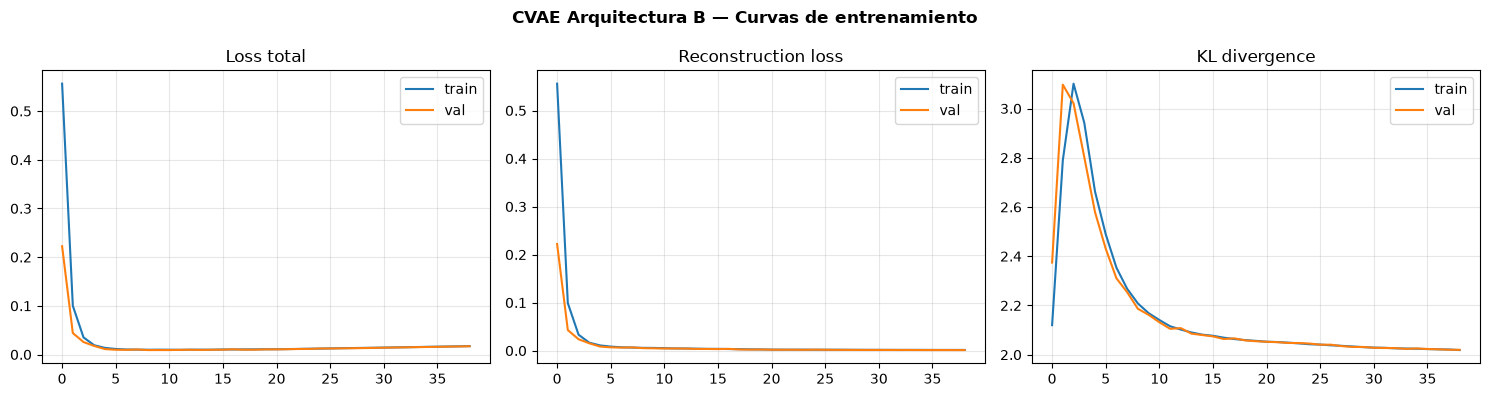

Mejor val loss: 0.0091


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history_b['train_loss'], label='train')
axes[0].plot(history_b['val_loss'],   label='val')
axes[0].set_title('Loss total')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_b['train_recon'], label='train')
axes[1].plot(history_b['val_recon'],   label='val')
axes[1].set_title('Reconstruction loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(history_b['train_kl'], label='train')
axes[2].plot(history_b['val_kl'],   label='val')
axes[2].set_title('KL divergence')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('CVAE Arquitectura B — Curvas de entrenamiento', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_b_training.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Mejor val loss: {history_b["best_val_loss"]:.4f}')

## 4. Evaluacion en validacion

In [22]:
provinces_val = data_b['provinces_val']

metrics_val_b, scenarios_val_b = full_evaluation(
    model_b, X_val, C_val, x_scaler_b,
    n_scenarios=500, device=DEVICE,
    provinces=provinces_val, architecture='B'
)

print('Metricas en validacion:')
print(f'  MAE global:      {metrics_val_b["mae_global"]:.1f} MWh')
print(f'  RMSE global:     {metrics_val_b["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:    {metrics_val_b["mape_energy"]:.2f}%')
print(f'  Coverage P5-P95: {metrics_val_b["coverage"]:.1f}%')
print(f'  Sharpness:       {metrics_val_b["sharpness"]:.1f} MWh')
print(f'  Diversity ratio: {metrics_val_b["diversity_ratio"]:.3f}')
print(f'  MMD:             {metrics_val_b["mmd"]:.4f}')

Generando 500 escenarios para 8052 muestras...
Calculando metricas...
Metricas en validacion:
  MAE global:      961.9 MWh
  RMSE global:     1205.5 MWh
  MAPE energia:    293.74%
  Coverage P5-P95: 70.9%
  Sharpness:       3710.6 MWh
  Diversity ratio: 0.739
  MMD:             0.0040


In [23]:
metrics_val_b['per_province']

,provincia,mae_mwh,coverage,sharpness
0,cordoba,2103.1,73.6,6363.500000
1,santa_fe,2089.7,86.7,6335.399902
2,mendoza,1970.6,42.9,6053.799805
3,buenos_aires,1774.6,42.5,2298.000000
4,san_luis,1426.1,16.3,4251.799805
5,chubut,1132.1,83.3,4738.000000
6,la_rioja,1030.2,48.9,4161.200195
7,salta,976.0,55.5,4250.700195
8,sgo_del_estero,929.1,63.7,4076.600098
9,rio_negro,858.3,79.0,4139.500000


## 5. Visualizacion de escenarios generados

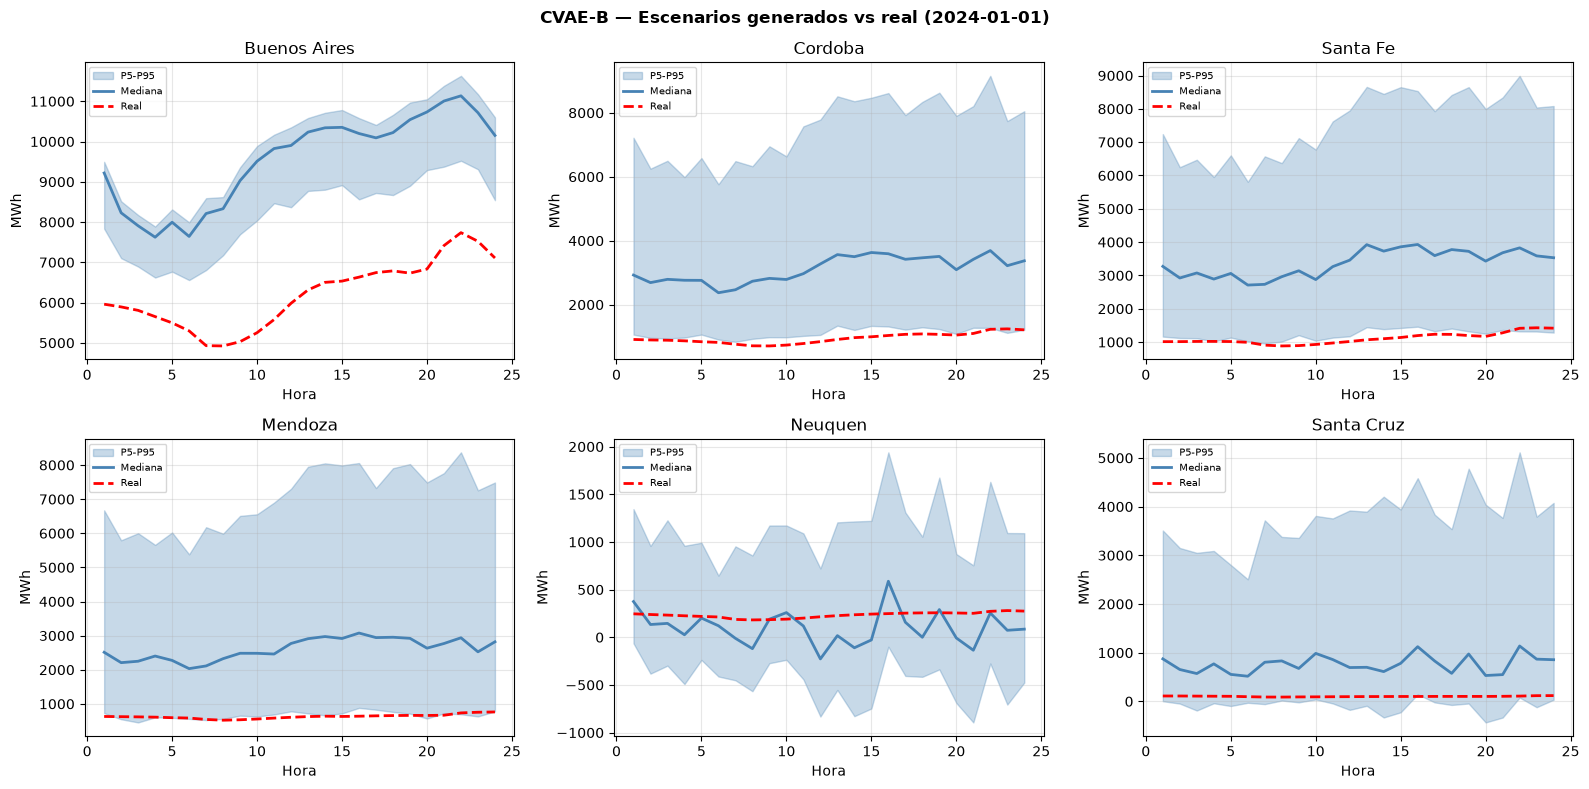

In [24]:
# Visualizar escenarios para 6 provincias en un dia de val
provinces_to_show = ['buenos_aires', 'cordoba', 'santa_fe', 'mendoza', 'neuquen', 'santa_cruz']
PROVINCE_ORDER = [
    'buenos_aires', 'catamarca', 'chaco', 'chubut', 'cordoba',
    'corrientes', 'entre_rios', 'formosa', 'jujuy', 'la_pampa',
    'la_rioja', 'mendoza', 'misiones', 'neuquen', 'rio_negro',
    'salta', 'san_juan', 'san_luis', 'santa_cruz', 'santa_fe',
    'sgo_del_estero', 'tucuman',
]

# En arch B, una fecha tiene 22 filas (una por provincia)
# Tomamos el primer dia del val set
first_date = pd.to_datetime(data_b['dates_val'])[0]
val_dates_ts = pd.to_datetime(data_b['dates_val'])

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, prov in zip(axes.flat, provinces_to_show):
    mask = (val_dates_ts == first_date) & (provinces_val == prov)
    if not mask.any():
        continue
    idx = np.where(mask)[0][0]
    real_mwh = x_scaler_b.inverse_transform(X_val[idx:idx+1]).flatten()
    scen_mwh = np.stack([
        x_scaler_b.inverse_transform(scenarios_val_b[idx, s:s+1, :]).flatten()
        for s in range(scenarios_val_b.shape[1])
    ])
    p5  = np.percentile(scen_mwh, 5,  axis=0)
    p50 = np.percentile(scen_mwh, 50, axis=0)
    p95 = np.percentile(scen_mwh, 95, axis=0)
    horas = range(1, 25)
    ax.fill_between(horas, p5, p95, alpha=0.3, color='steelblue', label='P5-P95')
    ax.plot(horas, p50,      color='steelblue', linewidth=2, label='Mediana')
    ax.plot(horas, real_mwh, color='red',       linewidth=2, label='Real', linestyle='--')
    ax.set_title(prov.replace('_', ' ').title())
    ax.set_xlabel('Hora')
    ax.set_ylabel('MWh')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle(f'CVAE-B — Escenarios generados vs real ({first_date.date()})', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_b_scenarios.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Resultado final en test

In [25]:
metrics_test_b, _ = full_evaluation(
    model_b, X_test, C_test, x_scaler_b,
    n_scenarios=500, device=DEVICE,
    provinces=provinces_test, architecture='B'
)

print('=== RESULTADO FINAL EN TEST — CVAE ARQUITECTURA B ===')
print(f'  MAE global:      {metrics_test_b["mae_global"]:.1f} MWh')
print(f'  RMSE global:     {metrics_test_b["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:    {metrics_test_b["mape_energy"]:.2f}%')
print(f'  Coverage P5-P95: {metrics_test_b["coverage"]:.1f}%')
print(f'  Sharpness:       {metrics_test_b["sharpness"]:.1f} MWh')
print(f'  Diversity ratio: {metrics_test_b["diversity_ratio"]:.3f}')
print(f'  MMD:             {metrics_test_b["mmd"]:.4f}')

Generando 500 escenarios para 10670 muestras...
Calculando metricas...
=== RESULTADO FINAL EN TEST — CVAE ARQUITECTURA B ===
  MAE global:      976.3 MWh
  RMSE global:     1224.9 MWh
  MAPE energia:    291.15%
  Coverage P5-P95: 71.8%
  Sharpness:       3796.8 MWh
  Diversity ratio: 0.746
  MMD:             0.0040


In [26]:
results_b = {
    'model': 'cvae_architecture_b',
    'val': {
        'mae_global':      float(round(metrics_val_b['mae_global'], 2)),
        'rmse_global':     float(round(metrics_val_b['rmse_global'], 2)),
        'mape_energy':     float(round(metrics_val_b['mape_energy'], 4)),
        'coverage':        float(round(metrics_val_b['coverage'], 2)),
        'sharpness':       float(round(metrics_val_b['sharpness'], 2)),
        'diversity_ratio': float(round(metrics_val_b['diversity_ratio'], 4)),
        'mmd':             float(round(metrics_val_b['mmd'], 6)),
    },
    'test': {
        'mae_global':      float(round(metrics_test_b['mae_global'], 2)),
        'rmse_global':     float(round(metrics_test_b['rmse_global'], 2)),
        'mape_energy':     float(round(metrics_test_b['mape_energy'], 4)),
        'coverage':        float(round(metrics_test_b['coverage'], 2)),
        'sharpness':       float(round(metrics_test_b['sharpness'], 2)),
        'diversity_ratio': float(round(metrics_test_b['diversity_ratio'], 4)),
        'mmd':             float(round(metrics_test_b['mmd'], 6)),
    },
}

with open(RESULTS_DIR / 'cvae_b_metrics.json', 'w') as f:
    json.dump(results_b, f, indent=2)
print('Metricas guardadas en results/cvae_b_metrics.json')


Metricas guardadas en results/cvae_b_metrics.json
